# EV Battery Health Prediction: Step 4, Explaining the Model with SHAP

In Step 3 I trained models to predict battery SOH. A model that gives a number is useful, but a model that can also say **why** it gave that number is much more trustworthy. In this notebook I use **SHAP** to look inside the model and check whether it relies on the right things.

| Step | What I do |
|---|---|
| 1 | Load the NASA data for one battery, calculate SOH, plot the capacity fade |
| 2 | Combine 4 batteries and explore the data |
| 3 | Train models to predict SOH |
| **4 (this notebook)** | **Explain the model with SHAP** |
| 5 | Predict Remaining Useful Life (RUL) |
| 6 | Build and deploy a Streamlit app |

## 1. What is SHAP?

SHAP (SHapley Additive exPlanations) splits a prediction into **contributions from each feature**.

A simple way to think about it: the model starts from an average prediction (the "base value"). Then every feature either pushes the prediction **up** or **down** from that average. SHAP tells how much each feature pushed, in the same units as the target, so here the units are **SOH percentage points**.

| Question | SHAP answer |
|---|---|
| Which features matter most overall? | Average size of the pushes (mean absolute SHAP value) |
| In which direction does a feature push? | Positive SHAP means it pushed SOH up, negative means down |
| Why did the model predict this value for this one cycle? | The list of pushes for that single row |

## 2. Importing libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBRegressor

c:\Users\ELCOT\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Loading the data and recreating the split

I use the same setup as Step 3: train on **B0005, B0006, B0007** and test on **B0018**. I explain the model on the unseen battery, because that shows how the model behaves on data it was not trained on.

In [3]:
df = pd.read_csv("all_batteries.csv")

TRAIN_BATTERIES = ["B0005", "B0006", "B0007"]
TEST_BATTERY = "B0018"
TARGET = "soh_percent"

FEATURES = [
    "avg_voltage",
    "min_voltage",
    "avg_current",
    "avg_temp",
    "max_temp",
    "discharge_time_s",
]

train = df[df["battery"].isin(TRAIN_BATTERIES)]
test = df[df["battery"] == TEST_BATTERY]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Training rows: {len(train)} | Testing rows: {len(test)} ({TEST_BATTERY})")

Training rows: 504 | Testing rows: 132 (B0018)


## 4. Training the model

I explain **XGBoost** here because SHAP has a fast and exact method (`TreeExplainer`) for tree-based models. The settings are the same as in Step 3.

If a different model turned out best in Step 3, the same steps work for it as long as it is tree-based, for example Random Forest.

In [4]:
model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
mae = np.mean(np.abs(y_test - pred))
print(f"MAE on {TEST_BATTERY}: {mae:.3f} SOH points")

MAE on B0018: 1.882 SOH points


## 5. Calculating SHAP values

SHAP gives one value per feature for **every row** of the test set. A positive value means that feature pushed the predicted SOH up for that cycle, and a negative value means it pushed it down.

In [5]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

print("SHAP values shape:", shap_values.shape, "(rows x features)")
print("Base value (average prediction):", float(np.ravel(explainer.expected_value)[0]))

SHAP values shape: (132, 6) (rows x features)
Base value (average prediction): 82.55374908447266


## 6. Which features matter most?

I averaged the **absolute** SHAP value of each feature across all test cycles. The bigger the average push, the more the model relies on that feature.

In [6]:
importance = (
    pd.DataFrame(
        {"feature": FEATURES, "mean_abs_shap": np.abs(shap_values).mean(axis=0)}
    )
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
    .round(3)
)

importance.to_csv("shap_importance.csv", index=False)
importance

,feature,mean_abs_shap
0,avg_voltage,5.725
1,avg_current,1.397
2,discharge_time_s,1.338
3,avg_temp,0.358
4,max_temp,0.287
5,min_voltage,0.132


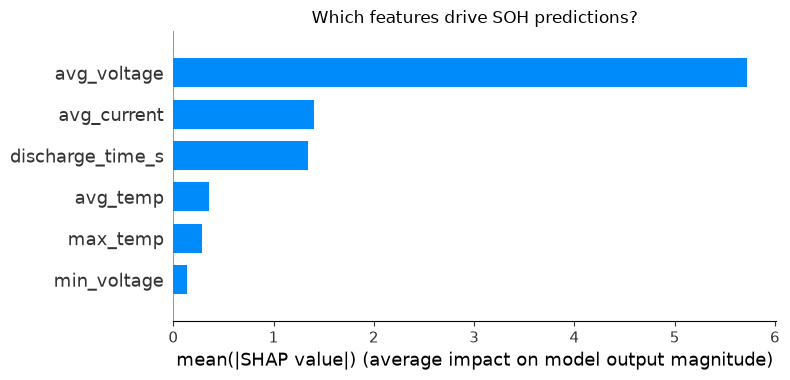

In [7]:
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("Which features drive SOH predictions?")
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=150)
plt.show()

## 7. How does each feature push the prediction?

The bar chart tells which features matter, but not **in which direction**. The beeswarm plot shows that.

How to read it:
- Each dot is one discharge cycle of the test battery.
- Position left or right: the SHAP value. Right means the feature pushed SOH **up**, left means it pushed SOH **down**.
- Colour: the feature's own value for that cycle. Red is high, blue is low.

For example, if the red dots of a feature sit on the right, high values of that feature push SOH up.

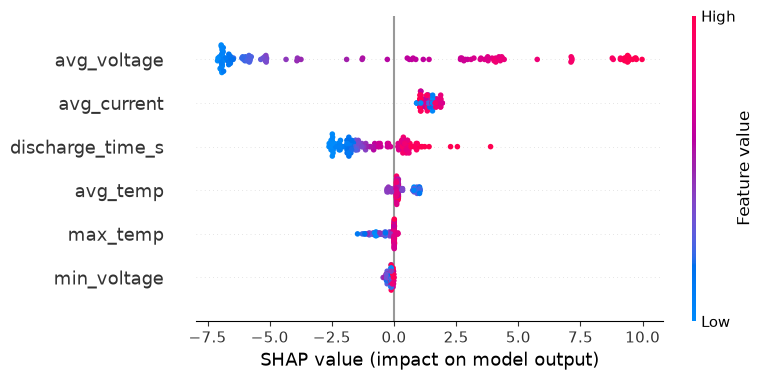

In [8]:
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=150)
plt.show()

## 8. Does it make physical sense?

A good model should agree with battery physics, not just fit the numbers. Things I check in the beeswarm plot:

| Expectation | Why |
|---|---|
| Longer discharge time should push SOH **up** | A healthy battery lasts longer on a discharge, and an aged one runs out sooner |
| Voltage-related features should relate to health in a consistent direction | Voltage behaviour during discharge changes as the battery ages |
| Temperature effects should be small or have a clear reason | Warmer batteries can behave differently, but temperature should not be the only thing the model relies on |

If the model does the opposite of physics for an important feature, it may be exploiting a quirk of the training batteries, and I would not trust it on new batteries.

## 9. Explaining one single prediction

SHAP can also explain **one cycle at a time**. I picked the last cycle of the test battery, which is where the battery is most worn out. The chart shows how each feature pushed the prediction away from the average.

In [9]:
idx = len(X_test) - 1
cycle_no = int(test["cycle"].iloc[idx])
actual = y_test.iloc[idx]
predicted = model.predict(X_test.iloc[[idx]])[0]

print(f"{TEST_BATTERY}, cycle {cycle_no}")
print(f"Actual SOH: {actual:.1f}%  |  Predicted SOH: {predicted:.1f}%")

contrib = pd.Series(shap_values[idx], index=FEATURES).sort_values()
contrib.round(3)

B0018, cycle 132
Actual SOH: 72.3%  |  Predicted SOH: 74.2%


avg_voltage        -6.993
discharge_time_s   -2.476
min_voltage        -0.121
max_temp            0.005
avg_temp            0.169
avg_current         1.042
dtype: float32

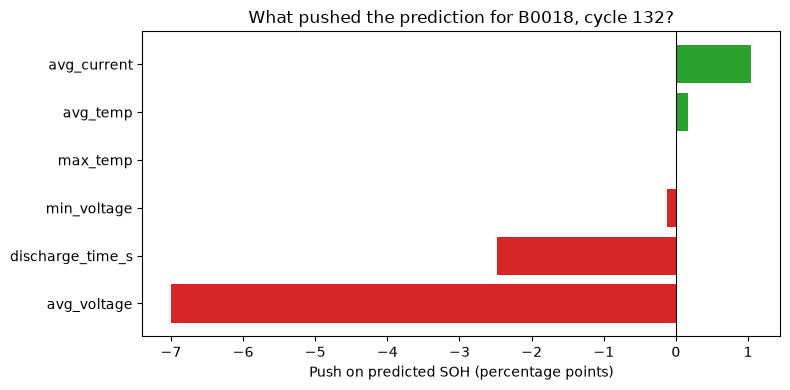

In [10]:
colors = ["tab:red" if v < 0 else "tab:green" for v in contrib.values]

plt.figure(figsize=(8, 4))
plt.barh(contrib.index, contrib.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"What pushed the prediction for {TEST_BATTERY}, cycle {cycle_no}?")
plt.xlabel("Push on predicted SOH (percentage points)")
plt.tight_layout()
plt.savefig("shap_single_prediction.png", dpi=150)
plt.show()

## 10. My observations from this run

- **Top feature(s) by importance:** `avg_voltage` by a wide margin (mean |SHAP| about 5.7 SOH points), then `avg_current` (about 1.4) and `discharge_time_s` (about 1.3). `avg_temp`, `max_temp` and `min_voltage` matter much less (0.4 or below).
- **Direction of the top feature (from the beeswarm):** high `avg_voltage` values (red) push the predicted SOH up and low values (blue) push it down, with the spread running from about -7 to +10 SOH points.
- **Does it match battery physics?** Mostly yes. Higher average voltage and a longer discharge time both push SOH up, which fits a healthy battery holding its voltage longer and lasting longer. `min_voltage` has almost no effect, which also makes sense because it mostly reflects the cut-off voltage of each test.
- **Role of temperature:** small. The temperature features have a much smaller effect than voltage, and `max_temp` pushes the prediction down only for some low values, so I would not read much into it.
- **Anything surprising:** `avg_current`. All of its SHAP values are positive for this test battery, and higher (less negative) current values seem to push SOH up. In the data, a more negative current goes with higher capacity (correlation about -0.88), so this looks like the opposite direction. The model may be using `avg_current` partly to tell the batteries apart rather than to measure health. Also, `avg_voltage` and `discharge_time_s` are strongly related to capacity, so the model leans on features that are very close to the thing it is predicting.

## 11. Limitations

- SHAP explains **what the model learned**, not necessarily what is true about the battery. If the model learned a quirk of the training batteries, SHAP will faithfully show that quirk.
- The explanation is for **one test battery** only. Features that look important here may rank differently on another battery.
- Features that are strongly related to each other (for example average and minimum voltage) can share credit between them, so their individual importance should be read with care.

## 12. Next step

In Step 5 I will predict **Remaining Useful Life (RUL)**: how many cycles are left before the battery reaches the end-of-life threshold.